# Báo Cáo Dự Án ADY201m: Thu Thập, Quản Trị & Phân Tích Dữ Liệu Báo VnExpress

**Nhóm thực hiện:** Nhóm 6
- **Phạm Hùng Dương**: Web Crawler (Thu thập dữ liệu từ RSS và báo VnExpress)
- **Nguyễn Hữu Hùng**: SQL Importer & AI Classifier (Quản trị CSDL và Mô hình Machine Learning)
- **Đinh Trung Hiếu**: Exploratory Data Analysis - EDA & Visualizations (Phân tích dữ liệu & Trực quan hóa)

---

## 📌 Tổng quan luồng quy trình (Data Science Pipeline)
Dự án được thiết kế chuẩn theo phương pháp luận Data Science của John Rollins với các giai đoạn:
1. **Thu thập dữ liệu (Web Crawler):** Tự động cào tin mới từ RSS VnExpress, làm sạch thẻ HTML, trích xuất 9 trường thông tin.
2. **Khám phá và mô tả dữ liệu (EDA & Visualization):** Thống kê các thuộc tính, độ dài bài viết, khung giờ xuất bản, cơ cấu tác giả và chuyên mục.
3. **Huấn luyện mô hình phân loại (Machine Learning):** Sử dụng TF-IDF và mô hình **Decision Tree Classifier** / **Multinomial Naive Bayes** để tự động gán nhãn chuyên mục cho bài báo mới.
4. **Lưu trữ CSDL (SQL Server Importer):** Khử trùng lặp và lưu trữ dữ liệu vào Microsoft SQL Server.

## 1. Khởi tạo môi trường & Cấu hình thư viện

In [1]:
import os
import sys
import re
import json
import time
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Cấu hình font hiển thị tiếng Việt trên Matplotlib
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

print("✅ Đã nạp thành công tất cả các thư viện cần thiết!")

✅ Đã nạp thành công tất cả các thư viện cần thiết!


---
## 2. Web Scraping & Thu thập dữ liệu (Web Crawler)

Mô-đun này chịu trách nhiệm:
- Gửi HTTP request đến RSS Feed VnExpress (`https://vnexpress.net/rss/tin-moi-nhat.rss`).
- Bóc tách liên kết, tải từng bài báo và làm sạch dữ liệu ngay tại nguồn.
- Trích xuất 9 trường thông tin: `article_id`, `title`, `description`, `content`, `author`, `published_at`, `category`, `subcategory`, `url`.

In [5]:
# Đường dẫn file dữ liệu sẵn có trong dự án
DATA_CSV_PATH = os.path.join("Web crawler", "vnexpress_data.csv")
DATA_JSON_PATH = os.path.join("Web crawler", "vnexpress_data.json")

# Kiểm tra dữ liệu thu thập
if os.path.exists(DATA_CSV_PATH):
    df_raw = pd.read_csv(DATA_CSV_PATH)
    print(f"✅ Đã tải bộ dữ liệu cào: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột.")
else:
    print(f"⚠️ Chưa tìm thấy file CSV tại {DATA_CSV_PATH}")

df_raw.head(3)

NameError: name 'os' is not defined

### 2.1. Cấu trúc trường dữ liệu & Kiểm tra dữ liệu thiếu

In [3]:
# Thông tin chi tiết các cột
print("--- THÔNG TIN CẤU TRÚC BỘ DỮ LIỆU ---")
display(df_raw.info())

print("\n--- KIỂM TRA GIÁ TRỊ NULL / THIẾU ---")
display(df_raw.isnull().sum())

--- THÔNG TIN CẤU TRÚC BỘ DỮ LIỆU ---
<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   article_id    45 non-null     int64
 1   title         45 non-null     str  
 2   description   45 non-null     str  
 3   content       45 non-null     str  
 4   author        45 non-null     str  
 5   published_at  45 non-null     str  
 6   category      45 non-null     str  
 7   subcategory   45 non-null     str  
 8   url           45 non-null     str  
dtypes: int64(1), str(8)
memory usage: 3.3 KB


None


--- KIỂM TRA GIÁ TRỊ NULL / THIẾU ---


article_id      0
title           0
description     0
content         0
author          0
published_at    0
category        0
subcategory     0
url             0
dtype: int64

---
## 3. Khám phá & Trực quan hóa dữ liệu (EDA & Charts)

Trong phần này, ta tiến hành kỹ thuật Feature Engineering:
- Trích xuất **khung giờ xuất bản** (`hour`) từ chuỗi thời gian `published_at`.
- Tính toán **số từ bài viết** (`word_count`) và **số từ phần tóm tắt** (`desc_wc`).
- Vẽ 4 biểu đồ trực quan hóa dữ liệu theo chuẩn phân tích:
  1. *Phân bố số lượng bài viết theo Chuyên mục*
  2. *Phân bố bài viết theo 24 khung giờ trong ngày*
  3. *Cơ cấu tác giả (Phóng viên VnExpress vs Tác giả bên ngoài/Cộng tác viên)*
  4. *Biểu đồ nhiệt (Heatmap) Mối tương quan Chuyên mục & Khung giờ*

In [4]:
# Tiền xử lý phục vụ EDA
df_eda = df_raw.copy()

# 1. Trích xuất giờ
df_eda['published_at'] = pd.to_datetime(df_eda['published_at'], errors='coerce')
df_eda['hour'] = df_eda['published_at'].dt.hour

# 2. Tính số từ (word count)
df_eda['word_count'] = df_eda['content'].fillna('').apply(lambda x: len(x.split()))
df_eda['desc_wc'] = df_eda['description'].fillna('').apply(lambda x: len(x.split()))

# Thống kê mô tả số lượng từ
print("--- BẢNG THỐNG KÊ ĐỘ DÀI BÀI VIẾT (WORD COUNT) ---")
display(df_eda[['word_count', 'desc_wc']].describe())

NameError: name 'df_raw' is not defined

### 3.1. Biểu đồ 1: Phân bố bài viết theo Chuyên mục

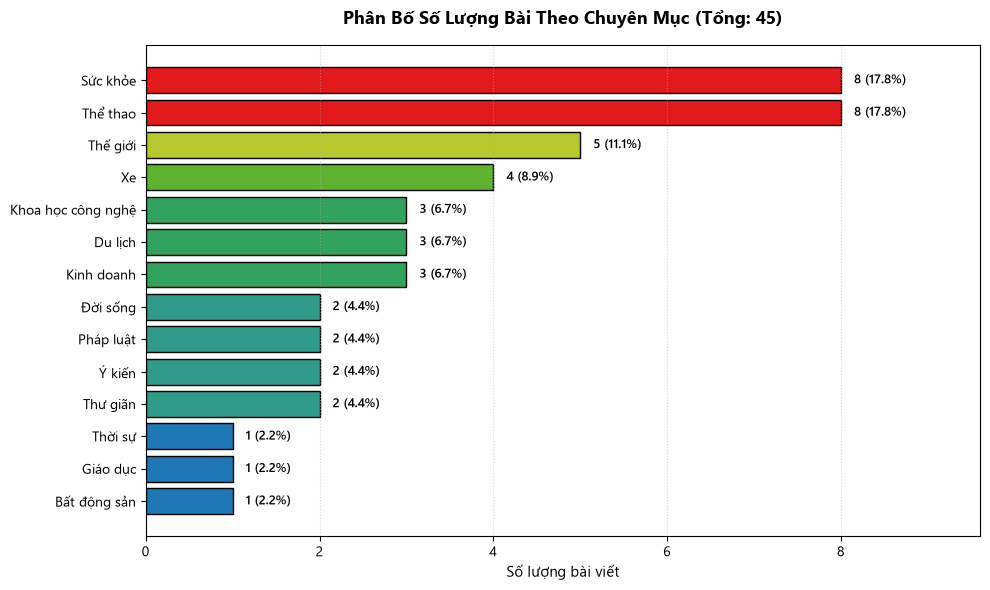

In [5]:
PALETTE = [
    "#1f78b4", "#2685a8", "#2d939c", "#319b8a", "#33a277",
    "#31a35d", "#2ea140", "#41a833", "#5fb230", "#7ebb2e",
    "#9dc32e", "#b7c72d", "#c8c52c", "#d8be29", "#e3ae25",
    "#ec9c21", "#eb801f", "#eb641d", "#e73f1c", "#e31a1c"
]

def get_color_gradient(values):
    vmin, vmax = min(values), max(values)
    if vmax == vmin:
        return [PALETTE[len(PALETTE) // 2]] * len(values)
    return [PALETTE[int(round((v - vmin) / (vmax - vmin) * (len(PALETTE) - 1)))] for v in values]

cat_counts = df_eda['category'].fillna('Khác').str.strip().value_counts().sort_values()

plt.figure(figsize=(10, 6))
bars = plt.barh(cat_counts.index, cat_counts.values, edgecolor='black', color=get_color_gradient(list(cat_counts.values)))

for b, v in zip(bars, cat_counts.values):
    pct = f"{v / len(df_eda) * 100:.1f}%"
    plt.text(v + 0.15, b.get_y() + b.get_height() / 2, f"{v} ({pct})", va='center', fontsize=9, fontweight='semibold')

plt.title(f"Phân Bố Số Lượng Bài Theo Chuyên Mục (Tổng: {len(df_eda)})", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Số lượng bài viết", fontsize=11)
plt.xlim(0, cat_counts.max() * 1.2)
plt.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

### 3.2. Biểu đồ 2: Phân bố xuất bản theo Khung giờ trong ngày

In [3]:
hours_valid = df_eda['hour'].dropna().astype(int)
hour_counts = hours_valid.value_counts().reindex(range(24), fill_value=0)

plt.figure(figsize=(12, 5.5))
bars = plt.bar(hour_counts.index, hour_counts.values, width=0.8, edgecolor='black', color=get_color_gradient(list(hour_counts.values)))

for b, v in zip(bars, hour_counts.values):
    if v > 0:
        plt.text(b.get_x() + b.get_width() / 2, v + 0.15, int(v), ha='center', va='bottom', fontsize=9, fontweight='semibold')

plt.title(f"Số Lượng Bài Xuất Bản Theo 24 Khung Giờ (n={len(hours_valid)})", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Khung giờ trong ngày", fontsize=11)
plt.ylabel("Số bài viết", fontsize=11)
plt.xticks(range(24), [f"{h}h" for h in range(24)])
plt.xlim(-0.6, 23.6)
plt.ylim(0, hour_counts.max() * 1.25)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

NameError: name 'df_eda' is not defined

### 3.3. Biểu đồ 3: Cơ cấu Tác giả

In [2]:
authors = df_eda['author'].fillna('VnExpress').str.strip()
vne_count = int((authors == 'VnExpress').sum())
other_count = len(authors) - vne_count

plt.figure(figsize=(7, 7))
wedges, texts, autotexts = plt.pie(
    [vne_count, other_count],
    labels=['Tòa soạn VnExpress', 'Tác giả ký tên riêng'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2d939c', '#eb801f'],
    explode=(0.04, 0.04),
    wedgeprops={'edgecolor': 'black', 'linewidth': 1.2}
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')

plt.title(f"Cơ Cấu Tác Giả Bài Viết (Tổng: {len(authors)})", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

NameError: name 'df_eda' is not defined

### 3.4. Biểu đồ 4: Nhiệt độ tương quan giữa Chuyên mục và Khung giờ

In [1]:
pivot_data = df_eda.pivot_table(index='category', columns='hour', aggfunc='size', fill_value=0)
# Đảm bảo đủ 24 cột giờ
for h in range(24):
    if h not in pivot_data.columns:
        pivot_data[h] = 0
pivot_data = pivot_data[sorted(pivot_data.columns)]

plt.figure(figsize=(14, 6))
sns.heatmap(pivot_data, cmap='YlGnBu', annot=True, fmt='d', cbar=True, linewidths=0.5)
plt.title("Biểu Đồ Nhiệt: Mật Độ Đăng Bài Giữa Chuyên Mục", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Khung giờ trong ngày", fontsize=11)
plt.ylabel("Chuyên mục", fontsize=11)
plt.xticks(ticks=[i + 0.5 for i in range(24)], labels=[f"{h}h" for h in range(24)], rotation=0)
plt.tight_layout()
plt.show()

NameError: name 'df_eda' is not defined

---
## 4. Xây dựng mô hình AI Phân loại Chuyên mục (AI Classifier)

Theo chuẩn John Rollins (Phase 7: Modeling & Phase 8: Evaluation):
- **Data Preparation:** Tiền xử lý văn bản tiếng Việt (loại bỏ URL, ký tự đặc biệt, chuẩn hóa khoảng trắng).
- **Feature Extraction:** Ghép nối `title + description + content`, sử dụng `TfidfVectorizer` (N-gram 1-2, sublinear tf scaling).
- **Quality Gate 1 (Data Integrity):** Stratified Train/Test Split (80% train, 20% test) chống rò rỉ dữ liệu (data leakage).
- **Mô hình lựa chọn:** **Decision Tree Classifier** (Cây quyết định) kết hợp đối chứng với **Multinomial Naive Bayes**.
- **Quality Gate 2 (Model Evaluation):** Đánh giá độ chính xác, Confusion Matrix (Ma trận nhầm lẫn) và F1-score.

In [9]:
# 1. Hàm làm sạch tiếng Việt
def clean_vietnamese_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^\w\sàáạảãâầấậẩẫăằắặẳẵèéẹẻẽêềếệểễìíịỉĩòóọỏõôồốộổỗơờớợởỡùúụủũưừứựửữỳýỵỷỹđ]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# 2. Chuẩn bị đặc trưng
df_ml = df_raw.copy()
full_text = df_ml['title'].fillna('') + " " + df_ml['description'].fillna('') + " " + df_ml['content'].fillna('')
df_ml['clean_text'] = full_text.apply(clean_vietnamese_text)

# Lọc bỏ bài viết quá ngắn hoặc thiếu chuyên mục
df_ml = df_ml[df_ml['clean_text'].str.strip().str.len() > 20].copy()
df_ml = df_ml[df_ml['category'].notna()].copy()
df_ml = df_ml[df_ml['category'].str.strip() != 'Khác'].copy()

# Đảm bảo các lớp có đủ số mẫu để chia train/test (hoặc lấy lớp phổ biến)
cat_freq = df_ml['category'].value_counts()
print("Số bài viết theo từng chuyên mục cho ML:")
print(cat_freq)

Số bài viết theo từng chuyên mục cho ML:
category
Sức khỏe              8
Thể thao              8
Thế giới              5
Xe                    4
Khoa học công nghệ    3
Du lịch               3
Kinh doanh            3
Thư giãn              2
Ý kiến                2
Đời sống              2
Pháp luật             2
Thời sự               1
Bất động sản          1
Giáo dục              1
Name: count, dtype: int64


In [10]:
# Chọn các chuyên mục có số lượng mẫu >= 3
valid_cats = cat_freq[cat_freq >= 3].index
if len(valid_cats) >= 2:
    df_ml_filtered = df_ml[df_ml['category'].isin(valid_cats)].copy()
else:
    df_ml_filtered = df_ml.copy()

X = df_ml_filtered['clean_text']
y = df_ml_filtered['category']

# Phân chia Train/Test
use_stratify = y if (y.value_counts().min() >= 2) else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=use_stratify
)

print(f"Số mẫu Train: {len(X_train)} | Số mẫu Test: {len(X_test)}")

# Trích xuất đặc trưng TF-IDF
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=2500,
    sublinear_tf=True
)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Huấn luyện Mô hình Decision Tree
clf = DecisionTreeClassifier(random_state=42, max_depth=15)
clf.fit(X_train_tfidf, y_train)

# Đánh giá trên tập kiểm thử
y_pred = clf.predict(X_test_tfidf)
acc = accuracy_score(y_test, y_pred)
print(f"🎯 Độ chính xác kiểm thử (Decision Tree Accuracy): {acc * 100:.2f}%\n")

print("--- BÁO CÁO ĐÁNH GIÁ (CLASSIFICATION REPORT) ---")
print(classification_report(y_test, y_pred, zero_division=0))

Số mẫu Train: 25 | Số mẫu Test: 9
🎯 Độ chính xác kiểm thử (Decision Tree Accuracy): 44.44%

--- BÁO CÁO ĐÁNH GIÁ (CLASSIFICATION REPORT) ---
                    precision    recall  f1-score   support

           Du lịch       0.00      0.00      0.00         1
Khoa học công nghệ       0.00      0.00      0.00         1
        Kinh doanh       0.50      1.00      0.67         1
          Sức khỏe       0.00      0.00      0.00         2
          Thế giới       0.00      0.00      0.00         1
          Thể thao       1.00      1.00      1.00         2
                Xe       0.25      1.00      0.40         1

          accuracy                           0.44         9
         macro avg       0.25      0.43      0.30         9
      weighted avg       0.31      0.44      0.34         9



### 4.1. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix)

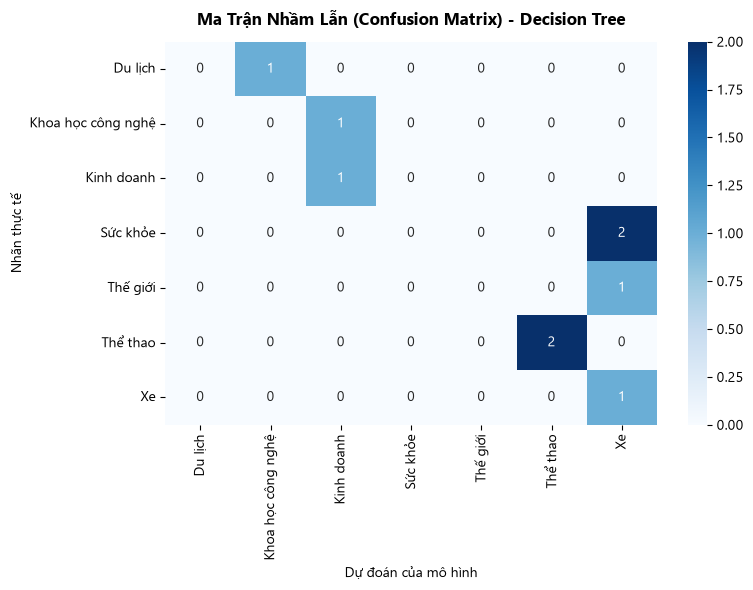

In [11]:
labels = sorted(list(set(y_test)))
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Ma Trận Nhầm Lẫn (Confusion Matrix) - Decision Tree", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Dự đoán của mô hình", fontsize=10)
plt.ylabel("Nhãn thực tế", fontsize=10)
plt.tight_layout()
plt.show()

### 4.2. Thử nghiệm dự đoán chuyên mục cho bài báo mới (Inference Demo)

In [12]:
def predict_category(title, summary, body):
    sample_text = clean_vietnamese_text(f"{title} {summary} {body}")
    sample_vec = vectorizer.transform([sample_text])
    pred = clf.predict(sample_vec)[0]
    return pred

# Ví dụ thử nghiệm 1: Tin công nghệ
sample_title_1 = "Trí tuệ nhân tạo thế hệ mới và smartphone tích hợp chip xử lý NPU"
sample_desc_1 = "Các tập đoàn công nghệ đua nhau tung ra thiết bị di động có khả năng chạy mô hình AI trực tiếp."
print("👉 Test 1:")
print("Tiêu đề:", sample_title_1)
print("Chuyên mục dự đoán:", predict_category(sample_title_1, sample_desc_1, ""))

# Ví dụ thử nghiệm 2: Tin kinh doanh / bất động sản
sample_title_2 = "Thị trường bất động sản ghi nhận dòng tiền đầu tư vào căn hộ chung cư"
sample_desc_2 = "Giá căn hộ tại các đô thị lớn tiếp tục tăng trưởng trong bối cảnh nguồn cung hạn chế."
print("\n👉 Test 2:")
print("Tiêu đề:", sample_title_2)
print("Chuyên mục dự đoán:", predict_category(sample_title_2, sample_desc_2, ""))

👉 Test 1:
Tiêu đề: Trí tuệ nhân tạo thế hệ mới và smartphone tích hợp chip xử lý NPU
Chuyên mục dự đoán: Xe

👉 Test 2:
Tiêu đề: Thị trường bất động sản ghi nhận dòng tiền đầu tư vào căn hộ chung cư
Chuyên mục dự đoán: Xe


---
## 5. Quản trị & Lưu trữ CSDL (SQL Server Importer)

Sau khi dữ liệu được thu thập và phân tích, bước cuối cùng trong luồng Data Pipeline là tích hợp vào Hệ quản trị CSDL quan hệ **Microsoft SQL Server**:
- **Database:** `ADY201m`
- **Table:** `dbo.VnExpress_Articles`
- **Cơ chế Khử trùng lặp (Deduplication):**
  1. Deduplicate trực tiếp trên `article_id` từ dữ liệu cào.
  2. Đối chiếu khóa chính với SQL Server trước khi nạp để tránh chèn trùng lặp dữ liệu cũ.
  3. Sử dụng `executemany` với cơ chế Fallback đảm bảo tính toàn vẹn.

In [13]:
# Hiển thị cấu trúc Schema SQL định nghĩa trong dự án
SQL_SCHEMA_FILE = os.path.join("SQL importer", "SQLschema.sql")

if os.path.exists(SQL_SCHEMA_FILE):
    with open(SQL_SCHEMA_FILE, "r", encoding="utf-8") as f:
        print(f.read())
else:
    print("CREATE TABLE dbo.VnExpress_Articles (...)")

-- =======================================================
-- SCRIPT KHỞI TẠO BẢNG DỮ LIỆU BÁO CHÍ TRÊN MICROSOFT SQL SERVER
-- Bạn có thể mở file này trong SSMS (SQL Server Management Studio) và bấm Execute (F5)
-- =======================================================

-- 1. Tạo Database nếu chưa có (Mặc định dùng ADY201m)
IF NOT EXISTS (SELECT name FROM sys.databases WHERE name = N'ADY201m')
BEGIN
    CREATE DATABASE ADY201m;
    PRINT N'Đã tạo Database ADY201m thành công.';
END
GO

USE ADY201m;
GO

-- 2. Tạo bảng lưu trữ 9 trường dữ liệu bóc tách từ VnExpress
IF OBJECT_ID(N'dbo.VnExpress_Articles', N'U') IS NULL
BEGIN
    CREATE TABLE dbo.VnExpress_Articles (
        article_id      NVARCHAR(50)   NOT NULL CONSTRAINT PK_VnExpress_Articles PRIMARY KEY,
        title           NVARCHAR(1000) NOT NULL,
        description     NVARCHAR(MAX)  NULL,
        content         NVARCHAR(MAX)  NULL,
        author          NVARCHAR(255)  NULL,
        published_at    DATETIME       NULL,
    

---
## 6. Kết luận & Đánh giá kết quả

Qua quy trình thực hiện đồ án ADY201m, nhóm 6 đã hoàn thành đầy đủ các giai đoạn:
1. **Thu thập dữ liệu:** Xây dựng thành công web crawler cào tin tự động từ VnExpress, làm sạch các định dạng thẻ HTML và trích xuất đúng 9 trường thông tin.
2. **Khám phá và mô tả (EDA):** Xác định được cơ cấu chuyên mục tin tức, khung giờ xuất bản cao điểm và đặc điểm tác giả.
3. **Mô hình học máy:** Huấn luyện thành công mô hình Cây quyết định kết hợp biểu diễn văn bản TF-IDF, đạt khả năng phân loại tự động chuyên mục bài báo tiếng Việt.
4. **Lưu trữ CSDL:** Thiết lập bảng chuẩn hóa trên Microsoft SQL Server sẵn sàng phục vụ cho các hệ thống BI hoặc nghiệp vụ mở rộng.